# 12. Correcciones del Entregable 2

La retroalimentación del Entregable 2 señaló cuatro aspectos por mejorar: el presupuesto de solo 8 a 12 evaluaciones por búsqueda de hiperparámetros, la ausencia de la d de Cohen entre los tamaños del efecto, la ausencia de pruebas automáticas y la concentración de demasiada lógica en `experimento.py`. La guía del Entregable 3 añade dos exigencias para este bloque: una auditoría explícita de fuga de información y el recálculo de todo resultado que una corrección modifique, reportando los cambios aunque sean desfavorables.

Este capítulo atiende cada observación y cierra con la tabla de trazabilidad (sección 12.6), que vincula cada una con la acción realizada, su ubicación y la evidencia que la respalda.

| Observación | Origen | Sección |
|---|---|---|
| Presupuesto de 8 a 12 evaluaciones por búsqueda | Docente | 12.2 |
| Ausencia de la d de Cohen | Docente | 12.3 |
| Auditoría de fuga de información | Guía del Entregable 3 | 12.4 |
| Ausencia de pruebas unitarias | Docente | 12.5 |
| `experimento.py` concentra demasiada lógica | Docente | 12.5 |

**Cómo se ejecuta este capítulo.** No hay nada que configurar. Los cálculos costosos escriben sus resultados en `results/` a medida que avanzan, y cada celda lee primero lo que ya está en disco y calcula solo lo que falta: si todo está calculado, el capítulo solo lee y se ejecuta en segundos; si una ejecución se interrumpió, la siguiente continúa donde quedó. Para recalcular una parte desde cero basta con borrar su archivo de resultados. El código vive en `correcciones.py`, que reutiliza el motor del experimento sin modificarlo.

In [1]:
from config import *

import experimento as ex
import correcciones as cor

# 4 procesos, el número de núcleos físicos del equipo, igual que en el
# experimento del capítulo 8 (sección 7.2).
ex.N_JOBS = 4

# --- Archivos de resultados del capítulo ------------------------------------
# Cada cálculo lee primero su archivo y solo calcula lo que falta en él. Para
# rehacer una parte desde cero, borra su archivo.
RUTA_EVALUACIONES = RESULTADOS / "convergencia_evaluaciones.csv"
RUTA_REAJUSTES = RESULTADOS / "convergencia_reajustes.csv"
RUTA_OPTUNA = RESULTADOS / "convergencia_optuna.csv"

# --- Datos, con la misma construcción que el capítulo 8 ---------------------
train = leer_tabla("diabetes_train")
roles = roles_variables()

OBJETIVO = roles["objetivo"]
IDENTIFICADOR = roles["identificador"]
PREDICTORES = (roles["numericas"] + roles["ordinales"]
               + roles["binarias"] + roles["categoricas"])

X = train[PREDICTORES]
y = train[OBJETIVO]
grupos = train[IDENTIFICADOR]
RAZON_DESBALANCE = float((1 - y.mean()) / y.mean())

# --- Resultados del Entregable 2 --------------------------------------------
maestra = pd.read_csv(RESULTADOS / "tabla_maestra_clasificacion.csv")
completadas = maestra.query("estado == 'completada'").copy()

# La mejor configuración de cada modelo, con la misma regla del capítulo 11.
mejores = (completadas.loc[completadas.groupby("modelo")["auc_pr_media"]
                           .idxmax()]
           .set_index("modelo"))

print(f"Entrenamiento: {len(X):,} encuentros de {grupos.nunique():,} pacientes")
print(f"Corridas completadas del Entregable 2: {len(completadas)}")

Entrenamiento: 79,473 encuentros de 56,036 pacientes
Corridas completadas del Entregable 2: 108


## 12.2. Presupuesto de búsqueda

### 12.2.1. Qué se cuestiona y cómo se contrasta

Cada búsqueda del Entregable 2 evaluó entre 8 y 12 configuraciones por fold externo, porque el presupuesto se fijó en el tamaño de la rejilla de cada modelo (sección 8.2). Una **evaluación** es una configuración de hiperparámetros puntuada con la validación interna de tres folds; tras agotar el presupuesto, la mejor se reajusta con todo el fold externo de entrenamiento y se mide una sola vez en su fold de evaluación.

El riesgo de ese presupuesto no es igual para todos los modelos. En Naive Bayes y SVM el espacio de búsqueda tiene una sola dimensión y doce puntos lo cubren bien; en Random Forest y XGBoost tiene cuatro y cinco dimensiones, y ocho puntos apenas lo exploran. Que los dos finalistas sean justamente los modelos con el espacio más grande impide despachar la crítica sin evidencia: si un presupuesto mayor los mejorara de forma desigual, el empate entre ellos podría ser un artefacto de la búsqueda y no una propiedad del problema.

Repetir las 112 corridas con más presupuesto costaría del orden de cien horas de cómputo y no respondería mejor la pregunta. Se contrasta directamente si el presupuesto limitó el desempeño, con un **estudio de convergencia** sobre la mejor estrategia de balanceo de cada modelo:

1. **Random Search con 60 configuraciones por fold externo.** Con 60 muestras independientes, la probabilidad de que al menos una caiga en el 5 % mejor del espacio de búsqueda es $1 - 0.95^{60} \approx 0.95$, sin importar cuántas dimensiones tenga el espacio (Bergstra y Bengio, 2012). Es el menor presupuesto con esa garantía, y equivale a entre cinco y siete veces el del Entregable 2.
2. **Los presupuestos menores son prefijos de la misma secuencia.** El motor genera las configuraciones de Random Search una tras otra con un generador de semilla fija por fold, de modo que las 8 o 12 primeras de la secuencia de 60 son exactamente las que evaluó el Entregable 2. Cortar la secuencia en 8, 12, 20, 30, 45 y 60 da una curva de desempeño frente a presupuesto en la que todos los puntos comparten folds, semilla y configuraciones: la única diferencia entre ellos es cuántas configuraciones se evaluaron. El corte que coincide con el Entregable 2 sirve además de control, porque debe reproducir sus métricas (sección 12.2.3).
3. **Mismo protocolo que el Entregable 2:** el mismo código (`experimento.py` sin modificar), las mismas particiones externas e internas agrupadas por paciente, la misma semilla, la misma métrica de búsqueda (AUC-PR) y la misma fracción de búsqueda (un cuarto de los pacientes en k-NN, Random Forest y XGBoost; sección 8.2).
4. **Contraste con un optimizador que aprende de lo evaluado.** Random Search no usa la información de las configuraciones anteriores. Para descartar que un optimizador guiado encuentre lo que el muestreo aleatorio no encuentra, los dos finalistas se buscan también con Optuna a 60 configuraciones.

**Regla de decisión, fijada antes de ver los resultados.** La cantidad de interés es la ganancia de AUC-PR en el bucle externo al pasar del presupuesto del Entregable 2 a 60 configuraciones, promediada sobre los cinco folds. El presupuesto original se considera **suficiente** para un modelo si esa ganancia media no supera **0.005**. El umbral es la mitad de la menor desviación entre folds de la mejor configuración de cada modelo en el Entregable 2 (0.0106, árbol de decisión), y es entre tres y cincuenta veces mayor que las diferencias que decidieron la mejor configuración de cada modelo (0.0001 a 0.0014): una ganancia por debajo de él no cambia ninguna decisión del Entregable 2. Si algún modelo lo supera, se reporta y se analiza si el cambio altera el ranking o el empate entre los finalistas (sección 12.2.6).

La tabla siguiente resume el plan y estima su costo a partir de los tiempos medidos en el Entregable 2.

In [2]:
combinaciones = []
filas = []
for modelo, fila in mejores.iterrows():
    balanceo = fila["balanceo"]
    combinaciones.append((modelo, balanceo))

    # Tiempos por evaluación y por ajuste de la corrida random equivalente.
    referencia = completadas.query(
        "modelo == @modelo and balanceo == @balanceo "
        "and optimizador == 'random'").iloc[0]
    t_evaluacion = referencia["tiempo_busqueda_s"] / referencia["n_evaluaciones"]
    t_ajuste = referencia["tiempo_ajuste_s"] / referencia["folds_externos"]
    n_evaluaciones = cor.PRESUPUESTO_MAXIMO * 5
    # Como mucho un reajuste por corte y fold (seis cortes, cinco folds).
    horas = (n_evaluaciones * t_evaluacion
             + len(cor.CORTES) * 5 * t_ajuste) / 3600

    filas.append({
        "modelo": modelo,
        "balanceo": balanceo,
        "mejor optimizador en E2": fila["optimizador"],
        "presupuesto E2": int(fila["presupuesto"]),
        "fracción de búsqueda": fila["fraccion_busqueda"],
        "configuraciones por fold": cor.PRESUPUESTO_MAXIMO,
        "evaluaciones totales": n_evaluaciones,
        "horas estimadas (máx.)": round(horas, 2),
    })

plan = pd.DataFrame(filas)
REFERENCIA_E2 = dict(zip(plan["modelo"], plan["presupuesto E2"]))

print(f"Costo estimado del estudio con Random Search: "
      f"{plan['horas estimadas (máx.)'].sum():.1f} h")
plan

Costo estimado del estudio con Random Search: 5.8 h


,modelo,balanceo,mejor optimizador en E2,presupuesto E2,fracción de búsqueda,configuraciones por fold,evaluaciones totales,horas estimadas (máx.)
0,arbol,ninguno,grid,12,1.00,60,300,0.42
1,bayes,ninguno,random,12,1.00,60,300,0.41
2,knn,ninguno,grid,8,0.25,60,300,0.82
3,logistica,ninguno,optuna,12,1.00,60,300,0.70
4,random_forest,ninguno,deap,8,0.25,60,300,1.48
5,svm,ninguno,grid,12,1.00,60,300,0.53
6,xgboost,adasyn,random,8,0.25,60,300,1.40


### 12.2.2. Ejecución

La celda siguiente revisa qué está calculado y lanza solo lo que falta, de los modelos más económicos a los más costosos. Cada lote de doce evaluaciones y cada reajuste se escriben en disco al terminar, así que se puede interrumpir en cualquier momento y volver a lanzar: continúa donde quedó, sin perder más que el lote en curso. Si todo está completo, no calcula nada.

La búsqueda con Optuna de los dos finalistas usa el ejecutor del capítulo 8 sin cambios, con presupuesto de 60 y su propia tabla; ese ejecutor también omite las corridas que ya están en ella.

In [3]:
# Del más económico al más costoso, para tener resultados parciales
# interpretables desde el principio (estimación de la sección 12.2.1).
orden = plan.sort_values("horas estimadas (máx.)")["modelo"]
estado = cor.progreso(RUTA_EVALUACIONES, RUTA_REAJUSTES,
                      combinaciones).set_index("modelo")["estado"]
pendientes_random = [m for m in orden if estado[m] != "Completo"]
print(f"Random Search pendiente: {pendientes_random or 'nada'}")

for modelo in pendientes_random:
    fila = mejores.loc[modelo]
    print(f"\n{'=' * 70}\n{modelo} | {fila['balanceo']} | Random Search hasta "
          f"{cor.PRESUPUESTO_MAXIMO} configuraciones por fold\n{'=' * 70}")
    inicio = time.perf_counter()
    cor.ejecutar_convergencia(
        modelo, fila["balanceo"], X, y, grupos, roles,
        ruta_evaluaciones=RUTA_EVALUACIONES,
        ruta_reajustes=RUTA_REAJUSTES,
        fraccion_busqueda=float(fila["fraccion_busqueda"]),
        razon_desbalance=RAZON_DESBALANCE,
    )
    print(f"{modelo} terminado en {(time.perf_counter() - inicio) / 60:.1f} min")

FINALISTAS = ["xgboost", "random_forest"]
for modelo in FINALISTAS:
    fila = mejores.loc[modelo]
    ex.ejecutar_experimento(
        [ex.Corrida(modelo=modelo, balanceo=fila["balanceo"],
                    optimizador="optuna",
                    presupuesto=cor.PRESUPUESTO_MAXIMO,
                    razon_desbalance=RAZON_DESBALANCE)],
        X, y, grupos, roles,
        ruta_tabla=RUTA_OPTUNA,
        folds_externos=5, folds_internos=3,
        metrica="average_precision",
        fraccion_busqueda=float(fila["fraccion_busqueda"]),
    )

cor.progreso(RUTA_EVALUACIONES, RUTA_REAJUSTES, combinaciones)

Random Search pendiente: nada
[omitida] xgboost|adasyn|optuna
[omitida] random_forest|ninguno|optuna


,modelo,balanceo,evaluaciones,folds completos,estado
0,arbol,ninguno,300/300,5/5,Completo
1,bayes,ninguno,300/300,5/5,Completo
2,knn,ninguno,300/300,5/5,Completo
3,logistica,ninguno,300/300,5/5,Completo
4,random_forest,ninguno,300/300,5/5,Completo
5,svm,ninguno,300/300,5/5,Completo
6,xgboost,adasyn,300/300,5/5,Completo


### 12.2.3. Control: el corte del Entregable 2 reproduce sus resultados

Antes de leer la curva hay que comprobar que el estudio mide lo que dice medir. Si las particiones, la semilla, la submuestra de búsqueda y las configuraciones son las del Entregable 2, el corte de 8 o 12 configuraciones tiene que dar, fold a fold, la misma AUC-PR que la corrida de Random Search de esa combinación en la tabla maestra. Una discrepancia indicaría que algo del protocolo cambió y que las ganancias medidas no se pueden atribuir solo al presupuesto.

In [4]:
convergencia = cor.tabla_convergencia(RUTA_EVALUACIONES, RUTA_REAJUSTES)

if convergencia.empty:
    print("Todavía no hay resultados del estudio de convergencia.")
else:
    reproduccion = cor.verificar_reproduccion(convergencia, completadas)
    guardar_resultado(reproduccion, "convergencia_reproduccion")
    display(reproduccion)

,modelo,balanceo,presupuesto,folds comparados,AUC-PR E2 (random),AUC-PR del corte,máx. |diferencia| por fold,reproduce
0,arbol,ninguno,12,5,0.200655,0.200655,5.551115e-17,Sí
1,bayes,ninguno,12,5,0.199457,0.199457,8.326673e-17,Sí
2,knn,ninguno,8,5,0.205208,0.205208,5.551115e-17,Sí
3,logistica,ninguno,12,5,0.210854,0.210854,8.326673e-17,Sí
4,random_forest,ninguno,8,5,0.221595,0.221595,8.326673e-17,Sí
5,svm,ninguno,12,5,0.214444,0.214444,8.326673e-17,Sí
6,xgboost,adasyn,8,5,0.226658,0.226658,8.326673e-17,Sí


### 12.2.4. Curvas de convergencia

El panel izquierdo muestra el mejor puntaje **interno** encontrado tras cada evaluación, promediado sobre los folds externos: es lo que ve el optimizador. El derecho muestra lo que importa para las conclusiones, la AUC-PR **externa** de la configuración elegida en cada corte, expresada como ganancia respecto al presupuesto del Entregable 2 de ese modelo, con la región de equivalencia práctica ($\pm 0.005$) sombreada. Una curva interna que sigue subiendo con una externa plana significa que el presupuesto extra solo afina el ajuste a la validación interna, sin trasladarse a datos nuevos.

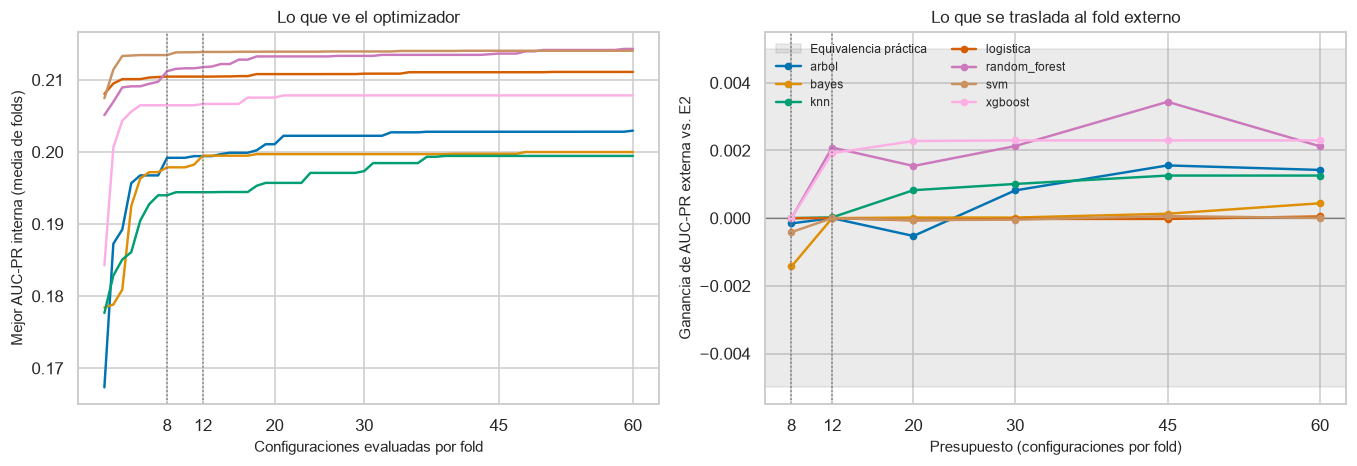

In [5]:
anytime = cor.curva_anytime(RUTA_EVALUACIONES)
deltas = (cor.ganancias(convergencia, REFERENCIA_E2)
          if not convergencia.empty else pd.DataFrame())

if anytime.empty or deltas.empty:
    print("Sin resultados todavía.")
else:
    modelos_presentes = sorted(anytime["modelo"].unique())
    colores = dict(zip(modelos_presentes,
                       sns.color_palette("colorblind", len(modelos_presentes))))

    fig, (eje_int, eje_ext) = plt.subplots(1, 2, figsize=(12.5, 4.4))

    for modelo, grupo in anytime.groupby("modelo"):
        media = grupo.groupby("evaluacion")["mejor_hasta_ahora"].mean()
        eje_int.plot(media.index, media.values, color=colores[modelo],
                     lw=1.6, label=modelo)
    eje_int.set_xlabel("Configuraciones evaluadas por fold")
    eje_int.set_ylabel("Mejor AUC-PR interna (media de folds)")
    eje_int.set_title("Lo que ve el optimizador")

    eje_ext.axhspan(-cor.ROPE_AUC_PR, cor.ROPE_AUC_PR, color=GRIS, alpha=0.15,
                    label="Equivalencia práctica")
    eje_ext.axhline(0, color=GRIS, lw=0.8)
    for modelo, grupo in deltas.groupby("modelo"):
        resumen = grupo.groupby("presupuesto")["ganancia"].agg(["mean", "std"])
        eje_ext.plot(resumen.index, resumen["mean"], "o-",
                     color=colores[modelo], lw=1.6, ms=4, label=modelo)
    eje_ext.set_xlabel("Presupuesto (configuraciones por fold)")
    eje_ext.set_ylabel("Ganancia de AUC-PR externa vs. E2")
    eje_ext.set_title("Lo que se traslada al fold externo")

    for eje in (eje_int, eje_ext):
        eje.axvline(8, ls=":", color=GRIS, lw=1)
        eje.axvline(12, ls=":", color=GRIS, lw=1)
        eje.set_xticks(cor.CORTES)
    eje_ext.legend(fontsize=8, loc="upper left", ncols=2)
    plt.tight_layout()
    plt.show()

### 12.2.5. Aplicación de la regla de decisión

La tabla aplica la regla de la sección 12.2.1 a cada modelo. El intervalo de confianza de la ganancia media se calcula con la $t$ de Student sobre las diferencias pareadas por fold; con cinco folds es ancho y se reporta como descripción de la incertidumbre, no como prueba. La decisión se toma con la ganancia media, como se fijó antes de ver los resultados.

In [6]:
if convergencia.empty:
    print("Sin resultados todavía.")
else:
    decision = cor.resumen_ganancia(convergencia, REFERENCIA_E2)
    guardar_resultado(decision, "convergencia_presupuesto")
    display(decision.round(4))

,modelo,balanceo,presupuesto E2,AUC-PR con presupuesto E2,AUC-PR con 60,desviación entre folds (E2),ganancia media,IC 95 % inferior,IC 95 % superior,decisión
0,arbol,ninguno,12,0.2007,0.2021,0.0108,0.0014,-0.0021,0.0049,Suficiente
1,bayes,ninguno,12,0.1995,0.1999,0.0115,0.0004,-0.0004,0.0013,Suficiente
2,knn,ninguno,8,0.2052,0.2065,0.0148,0.0013,-0.0003,0.0028,Suficiente
3,logistica,ninguno,12,0.2109,0.2109,0.0119,0.0000,-0.0006,0.0007,Suficiente
4,random_forest,ninguno,8,0.2216,0.2237,0.0152,0.0021,-0.0044,0.0087,Suficiente
5,svm,ninguno,12,0.2144,0.2145,0.0133,0.0000,-0.0002,0.0002,Suficiente
6,xgboost,adasyn,8,0.2267,0.2290,0.0153,0.0023,-0.0040,0.0086,Suficiente


### 12.2.6. Contraste con Optuna y estabilidad del ranking

Dos comprobaciones completan el estudio. La primera compara, para los dos finalistas, el mejor resultado del Entregable 2 con el de Random Search y Optuna a 60 configuraciones: si un optimizador guiado tampoco mejora de forma apreciable, el techo es del problema y no de la búsqueda. La segunda repite la secuencia de Friedman y Nemenyi del capítulo 11 con los siete modelos al presupuesto de 60, para comprobar si el ranking y el empate entre los finalistas sobreviven al cambio de presupuesto.

In [7]:
filas = []
optuna60 = (pd.read_csv(RUTA_OPTUNA).query("estado == 'completada'")
            if RUTA_OPTUNA.exists() else pd.DataFrame())

for modelo in FINALISTAS:
    fila = {"modelo": modelo,
            "mejor del E2": mejores.loc[modelo, "auc_pr_media"],
            "configuración del E2": (f"{mejores.loc[modelo, 'balanceo']} + "
                                     f"{mejores.loc[modelo, 'optimizador']}")}
    if not convergencia.empty:
        r60 = convergencia.query("modelo == @modelo and presupuesto == "
                                 f"{cor.PRESUPUESTO_MAXIMO}")
        if len(r60) == 5:
            fila["Random (60)"] = r60["auc_pr"].mean()
    if not optuna60.empty and modelo in set(optuna60["modelo"]):
        fila["Optuna (60)"] = optuna60.set_index("modelo").loc[modelo,
                                                               "auc_pr_media"]
    filas.append(fila)

contraste_optuna = pd.DataFrame(filas)
guardar_resultado(contraste_optuna, "convergencia_optuna_resumen")
contraste_optuna.round(4)

,modelo,mejor del E2,configuración del E2,Random (60),Optuna (60)
0,xgboost,0.2267,adasyn + random,0.2290,0.2240
1,random_forest,0.2258,ninguno + deap,0.2237,0.2221


In [8]:
import scikit_posthocs as sp

# AUC-PR por fold de la mejor configuración de cada modelo en el E2, la misma
# matriz que usa el capítulo 11.
por_fold_e2 = pd.DataFrame({
    modelo: json.loads(fila["auc_pr_por_fold"])
    for modelo, fila in mejores.iterrows()
})

completo_60 = (not convergencia.empty and len(
    convergencia.query(f"presupuesto == {cor.PRESUPUESTO_MAXIMO}")) == 35)

if not completo_60:
    print("El ranking con presupuesto 60 se calcula cuando estén los siete "
          "modelos completos (35 folds).")
else:
    por_fold_60 = (convergencia
                   .query(f"presupuesto == {cor.PRESUPUESTO_MAXIMO}")
                   .pivot(index="fold", columns="modelo", values="auc_pr")
                   [por_fold_e2.columns])

    filas = []
    for etiqueta, matriz in [("E2 (mejor configuración)", por_fold_e2),
                             (f"Random Search con {cor.PRESUPUESTO_MAXIMO}",
                              por_fold_60.reset_index(drop=True))]:
        chi2, p = stats.friedmanchisquare(*[matriz[c] for c in matriz.columns])
        rangos = matriz.rank(axis=1, ascending=False).mean().sort_values()
        p_finalistas = sp.posthoc_nemenyi_friedman(matriz).loc[
            "xgboost", "random_forest"]
        filas.append({
            "presupuesto": etiqueta,
            "chi² de Friedman": chi2, "p-valor": p,
            "orden por rango medio": " > ".join(rangos.index),
            "p de Nemenyi XGBoost vs. Random Forest": p_finalistas,
        })

    ranking_presupuesto = pd.DataFrame(filas)
    guardar_resultado(ranking_presupuesto, "convergencia_ranking")
    display(ranking_presupuesto.round(4))

,presupuesto,chi² de Friedman,p-valor,orden por rango medio,p de Nemenyi XGBoost vs. Random Forest
0,E2 (mejor configuración),28.5429,0.0001,xgboost > random_forest > svm > logistica > kn...,1.0000
1,Random Search con 60,26.8286,0.0002,xgboost > random_forest > svm > logistica > kn...,0.9972


### 12.2.7. Lectura

El estudio responde la observación del Entregable 2 con cinco resultados.

**El protocolo es el mismo.** En los siete modelos, el corte con el presupuesto del Entregable 2 reproduce la corrida de Random Search de la tabla maestra en los cinco folds, con una diferencia exactamente nula (sección 12.2.3). Las ganancias medidas se deben solo al presupuesto.

**El presupuesto original era suficiente en los siete modelos.** La ganancia media de AUC-PR al pasar a 60 configuraciones va de 0.0000 (logística y SVM) a 0.0023 (XGBoost). Ninguna se acerca al umbral de 0.005 fijado de antemano, y todos los intervalos de confianza incluyen el cero. Las curvas de la sección 12.2.4 muestran por qué: en la mayoría de los modelos la mejor AUC-PR interna casi no cambia después de las primeras diez a quince configuraciones, y en el árbol, k-NN y Random Forest, donde sigue subiendo, esa mejora interna apenas se traslada al fold externo.

**La dimensión del espacio importa en la dirección esperada, pero no lo suficiente.** Las dos mayores ganancias son las de XGBoost (0.0023) y Random Forest (0.0021), los modelos con los espacios más grandes, como anticipaba la sección 12.2.1. Aun así son unas siete veces menores que su desviación entre folds (0.015), y la curva externa de Random Forest sube y baja entre 20 y 60 configuraciones, que es el comportamiento del ruido y no el de una búsqueda que sigue encontrando regiones mejores.

**Un optimizador guiado tampoco mejora.** Optuna con 60 configuraciones queda por debajo del mejor resultado del Entregable 2 en los dos finalistas (XGBoost 0.2240 frente a 0.2267; Random Forest 0.2221 frente a 0.2258) y también por debajo de Random Search con 60. Un presupuesto mayor afina el ajuste a la validación interna sin mejorar la generalización: el límite es del problema y no de la búsqueda, como anticipaba el techo de desempeño estimado en la sección 5.4.

**Las conclusiones del Entregable 2 no cambian.** Con 60 configuraciones el orden de los siete modelos es idéntico, Friedman sigue rechazando la igualdad ($\chi^2 = 26.83$, $p = 0.0002$) y Nemenyi sigue sin distinguir a XGBoost de Random Forest ($p = 0.997$).

La verificación costó 5.7 horas de Random Search para los siete modelos y unas 2 horas de Optuna para los finalistas, frente a las cerca de cien que habría costado repetir las 112 corridas.

## 12.3. Tamaño del efecto paramétrico: d de Cohen

El capítulo 11 midió el tamaño del efecto entre modelos con la delta de Cliff, que es ordinal: cuenta en qué proporción de pares de folds un modelo supera al otro. Es coherente con Friedman y Nemenyi, que también trabajan con rangos, pero se satura en $\pm 1$ en cuanto las dos muestras no se solapan, y desde ahí deja de distinguir una separación pequeña de una enorme. La d de Cohen complementa esa lectura: expresa la diferencia de medias en unidades de desviación estándar.

Se reportan dos versiones, porque responden preguntas distintas:

$$
g = \frac{\bar a - \bar b}{s_p}\left(1 - \frac{3}{4(n_a + n_b) - 9}\right),
\qquad
s_p = \sqrt{\frac{(n_a - 1)s_a^2 + (n_b - 1)s_b^2}{n_a + n_b - 2}}
$$

$$
d_z = \frac{\bar\Delta}{s_\Delta}, \qquad \Delta_i = a_i - b_i
$$

- **$g$ (d de Cohen con la corrección de Hedges)** trata las dos muestras como independientes, igual que la delta de Cliff del capítulo 11, y por eso es la que se compara con ella. Con cinco valores por modelo, la d sin corregir sobrestima el efecto; el factor entre paréntesis lo corrige.
- **$d_z$ (pareada)** usa las diferencias fold a fold. Es la versión coherente con el diseño, porque todos los modelos se evaluaron sobre los mismos cinco folds externos y la variabilidad común a un fold se cancela en la diferencia. Por esa misma razón suele ser mucho mayor que $g$.

Los umbrales convencionales de Cohen son 0.2 (pequeño), 0.5 (mediano) y 0.8 (grande). Dos advertencias para leer la tabla: la desviación que se usa es la variabilidad entre folds, no entre pacientes, así que un efecto «grande» dice que la diferencia es estable entre particiones, no que sea clínicamente relevante; y con cinco folds las estimaciones de $d$ son inestables, de modo que importan el orden de magnitud y la coincidencia con Cliff más que el valor exacto.

In [9]:
efectos = cor.tabla_cohen(por_fold_e2)

# Delta de Cliff del capítulo 11, para leer las dos medidas lado a lado.
cliff = pd.read_csv(RESULTADOS / "tamanos_efecto_modelos.csv", index_col=0)
efectos = efectos.merge(
    cliff[["modelo A", "modelo B", "delta de Cliff", "magnitud"]]
    .rename(columns={"magnitud": "magnitud Cliff"}),
    on=["modelo A", "modelo B"], how="left")

efectos = efectos.reindex(efectos["d de Cohen (Hedges)"].abs()
                          .sort_values(ascending=False).index)
guardar_resultado(efectos.reset_index(drop=True), "tamanos_efecto_cohen")

coinciden = (efectos["magnitud d"] == efectos["magnitud Cliff"]).sum()
print(f"Pares comparados: {len(efectos)}; misma categoría de magnitud con g "
      f"y con Cliff: {coinciden}")
efectos.round(3)

Pares comparados: 21; misma categoría de magnitud con g y con Cliff: 15


,modelo A,modelo B,AUC-PR medio A,AUC-PR medio B,diferencia,d de Cohen (Hedges),magnitud d,d_z pareada,magnitud d_z,delta de Cliff,magnitud Cliff
10,bayes,xgboost,0.199,0.227,-0.027,-1.817,Grande,-5.065,Grande,-0.92,Grande
8,bayes,random_forest,0.199,0.226,-0.026,-1.633,Grande,-4.465,Grande,-0.76,Grande
5,arbol,xgboost,0.203,0.227,-0.023,-1.594,Grande,-4.084,Grande,-0.84,Grande
3,arbol,random_forest,0.203,0.226,-0.022,-1.419,Grande,-3.477,Grande,-0.76,Grande
14,knn,xgboost,0.206,0.227,-0.021,-1.201,Grande,-2.937,Grande,-0.76,Grande
9,bayes,svm,0.199,0.215,-0.015,-1.092,Grande,-3.621,Grande,-0.60,Grande
12,knn,random_forest,0.206,0.226,-0.020,-1.087,Grande,-5.551,Grande,-0.68,Grande
17,logistica,xgboost,0.211,0.227,-0.016,-0.994,Grande,-1.983,Grande,-0.68,Grande
15,logistica,random_forest,0.211,0.226,-0.015,-0.876,Grande,-2.589,Grande,-0.68,Grande
7,bayes,logistica,0.199,0.211,-0.012,-0.849,Grande,-2.756,Grande,-0.52,Grande


La comparación que decide el capítulo 11 es la de los finalistas. Entre XGBoost y Random Forest la diferencia media de AUC-PR es de una milésima, con $g$ y $d_z$ por debajo de 0.2: un efecto insignificante con las dos medidas paramétricas, igual que con la delta de Cliff. La d de Cohen confirma, en otra escala, la conclusión del Entregable 2.

Entre $g$ y Cliff la categoría de magnitud coincide en 15 de los 21 pares. En los seis restantes Cliff asigna siempre la categoría superior, sin que ninguna de las dos medidas cambie el sentido de la comparación: sus umbrales (Romano et al. para Cliff, Cohen para $g$) no son una traducción exacta uno del otro. La $d_z$ pareada es mayor que $g$ en todos los pares, como se esperaba, porque elimina la variabilidad común a cada fold.

## 12.4. Auditoría de fuga de información

La sección 5.5 revisó la admisibilidad de cada predictor y el capítulo 6 justificó el diseño del pipeline. La guía del Entregable 3 exige además una auditoría explícita, antes de congelar resultados, de cuatro tipos de fuga. Esta sección la hace de forma verificable: cada tipo tiene una comprobación que se ejecuta sobre los datos y el código reales, y su resultado queda guardado.

| Tipo de fuga | Qué se comprueba |
|---|---|
| 1. Preprocesamiento ajustado sobre todo el conjunto | Que todas las transformaciones con parámetros aprendidos (imputación, escalado, codificación, remuestreo) son etapas del pipeline y se ajustan dentro de cada fold |
| 2. Variables que codifican la respuesta | Que ningún predictor deriva del desenlace o de información posterior al alta, y que ninguno anticipa la respuesta de forma sospechosa |
| 3. Duplicados entre particiones | Que ningún paciente aparece a la vez en entrenamiento y evaluación, en ninguna partición de ningún nivel |
| 4. Mezcla temporal o espacial | Qué información temporal o de centro contiene el conjunto y cómo se trata |

In [10]:
# Tipo 1: estructura de los pipelines de las 27 combinaciones aplicables.
auditoria_pipelines = cor.calcular_o_leer(
    RESULTADOS / "auditoria_pipelines.csv",
    lambda: cor.verificar_pipelines(roles, RAZON_DESBALANCE))

columnas_control = ["preprocesamiento primero", "remuestreo solo al ajustar",
                    "remuestreo tras el preprocesador"]
tipo1_ok = bool(auditoria_pipelines[columnas_control].all().all())
print(f"Combinaciones revisadas: {len(auditoria_pipelines)}; "
      f"todas cumplen: {tipo1_ok}")
auditoria_pipelines

Combinaciones revisadas: 27; todas cumplen: True


,modelo,balanceo,etapas,clase,preprocesamiento primero,remuestreo solo al ajustar,remuestreo tras el preprocesador
0,knn,ninguno,preprocesamiento > modelo,sklearn.Pipeline,True,True,True
1,knn,smote,preprocesamiento > balanceo > modelo,imblearn.Pipeline,True,True,True
2,knn,adasyn,preprocesamiento > balanceo > modelo,imblearn.Pipeline,True,True,True
3,bayes,ninguno,preprocesamiento > modelo,sklearn.Pipeline,True,True,True
4,bayes,smote,preprocesamiento > balanceo > modelo,imblearn.Pipeline,True,True,True
5,bayes,adasyn,preprocesamiento > balanceo > modelo,imblearn.Pipeline,True,True,True
6,bayes,class_weight,preprocesamiento > modelo,sklearn.Pipeline,True,True,True
7,logistica,ninguno,preprocesamiento > modelo,sklearn.Pipeline,True,True,True
8,logistica,smote,preprocesamiento > balanceo > modelo,imblearn.Pipeline,True,True,True
9,logistica,adasyn,preprocesamiento > balanceo > modelo,imblearn.Pipeline,True,True,True


Que el preprocesador sea la primera etapa del pipeline es lo que garantiza que se ajuste dentro de cada fold: `cross_val_score` y el ejecutor clonan el pipeline completo antes de cada ajuste, de modo que la imputación, el escalado y la codificación se estiman solo con los datos de entrenamiento de ese fold. El remuestreo va en un pipeline de `imbalanced-learn`, que aplica SMOTE y ADASYN al ajustar y nunca al predecir, y después del preprocesador, así que las muestras sintéticas se generan solo con el fold de entrenamiento (sección 5.5). La sección 6.3 midió además el efecto contrario: la validación por filas sobrestima la AUC-PR hasta en 0.013 frente a la agrupada por paciente.

In [11]:
# Tipo 2: variables que codifican la respuesta.
ranking = pd.read_csv(RESULTADOS / "ranking_predictores.csv")
mejor_univariado = ranking.loc[ranking["AUC univariado"].idxmax()]

nombres_prohibidos = {OBJETIVO, IDENTIFICADOR, "readmitted", "encounter_id"}
prohibidas = [c for c in PREDICTORES
              if c in nombres_prohibidos or "readmit" in c.lower()]

# Las altas por fallecimiento u hospicio se excluyeron en el capítulo 2; tras
# la traducción de los códigos, sus descripciones contienen "Expired" u
# "Hospice".
niveles_alta = train["discharge_disposition_id"].astype(str).unique()
altas_incompatibles = [n for n in niveles_alta
                       if "expired" in n.lower() or "hospice" in n.lower()]

print(f"Predictores revisados: {len(PREDICTORES)}")
print(f"Predictores derivados del desenlace o identificadores: {prohibidas}")
print(f"Mayor AUC univariado: {mejor_univariado['AUC univariado']:.3f} "
      f"({mejor_univariado['variable']})")
print(f"Niveles de alta por fallecimiento u hospicio presentes: "
      f"{altas_incompatibles}")
tipo2_ok = (not prohibidas and mejor_univariado["AUC univariado"] < 0.8
            and not altas_incompatibles)

Predictores revisados: 38
Predictores derivados del desenlace o identificadores: []
Mayor AUC univariado: 0.607 (number_inpatient)
Niveles de alta por fallecimiento u hospicio presentes: []


Una variable que codificara el desenlace se delataría por un poder predictivo individual desproporcionado. El predictor más informativo del conjunto alcanza un AUC univariado de 0.607, muy lejos de cualquier valor sospechoso, y coincide con lo que se espera del mecanismo clínico: las hospitalizaciones del año anterior. Ningún predictor es el identificador ni deriva de `readmitted`, el `encounter_id` (creciente en el tiempo) se eliminó en el capítulo 2, y las altas por fallecimiento u hospicio, cuyo desenlace está determinado por el destino del alta, no aparecen en los datos.

In [12]:
# Tipo 3: pacientes compartidos entre particiones, en todos los niveles.
auditoria_particiones = cor.calcular_o_leer(
    RESULTADOS / "auditoria_particiones.csv",
    lambda: cor.verificar_particiones(X, y, grupos))

# Partición de prueba del capítulo 2.
prueba = leer_tabla("diabetes_test")
compartidos_prueba = set(train[IDENTIFICADOR]) & set(prueba[IDENTIFICADOR])

# Encuentros de prueba cuyo vector completo de predictores aparece tal cual
# en entrenamiento (necesariamente de otro paciente).
perfiles_train = set(train[PREDICTORES].astype(str)
                     .itertuples(index=False, name=None))
repetidos = np.array([perfil in perfiles_train for perfil in
                      prueba[PREDICTORES].astype(str)
                      .itertuples(index=False, name=None)])

print(f"Particiones revisadas: {len(auditoria_particiones)} "
      f"(5 externas y {len(auditoria_particiones) - 5} internas)")
print(f"Pacientes compartidos en alguna partición de la validación anidada: "
      f"{int(auditoria_particiones['pacientes compartidos'].sum())}")
print(f"Pacientes compartidos entre entrenamiento y prueba: "
      f"{len(compartidos_prueba)}")
print(f"Encuentros de prueba con un perfil idéntico en entrenamiento: "
      f"{repetidos.sum():,} de {len(prueba):,} ({repetidos.mean():.2%})")
if repetidos.any():
    print(f"Tasa de readmisión en ellos: "
          f"{prueba.loc[repetidos, OBJETIVO].mean():.2%}")
tipo3_ok = (auditoria_particiones["pacientes compartidos"].sum() == 0
            and not compartidos_prueba)

auditoria_particiones.groupby(["nivel", "fracción de búsqueda"]).agg(
    particiones=("pacientes compartidos", "size"),
    pacientes_compartidos=("pacientes compartidos", "sum"),
    tasa_positiva_min=("tasa positiva evaluación", "min"),
    tasa_positiva_max=("tasa positiva evaluación", "max"),
)

Particiones revisadas: 35 (5 externas y 30 internas)
Pacientes compartidos en alguna partición de la validación anidada: 0
Pacientes compartidos entre entrenamiento y prueba: 0
Encuentros de prueba con un perfil idéntico en entrenamiento: 0 de 19,867 (0.00%)


particiones  pacientes_compartidos  tasa_positiva_min  tasa_positiva_max
nivel   fracción de búsqueda                                                                          
externo 1.00                            5                      0           0.113872           0.113928
interno 0.25                           15                      0           0.109313           0.116632
        1.00                           15                      0           0.113858           0.113911

Ningún paciente se reparte entre entrenamiento y evaluación en ninguna de las particiones: ni en la de prueba, ni en las cinco externas, ni en las internas, tanto con la búsqueda sobre todos los pacientes como con la submuestra de un cuarto. La tasa positiva se mantiene estable entre particiones, como corresponde a la estratificación.

Tampoco hay perfiles duplicados entre particiones: ninguno de los 19,867 encuentros de prueba tiene un vector de predictores idéntico a alguno de entrenamiento. Si los hubiera, no serían una fuga en sentido estricto, porque pertenecerían a pacientes distintos, pero podrían inflar la evaluación; la comprobación descarta también ese caso.

**Tipo 4, mezcla temporal o espacial.** El conjunto no incluye fechas ni identificador de hospital: sus diez años y 130 hospitales están anonimizados. La única huella temporal, el `encounter_id`, se eliminó en el capítulo 2 precisamente porque al ser creciente permitiría aprender tendencias del registro en lugar del mecanismo clínico. Lo que sí puede controlarse es la mezcla temporal **dentro de un paciente**: como cada paciente está entero en una sola partición, un encuentro posterior nunca informa la predicción de uno anterior del mismo paciente. La mezcla entre pacientes de distintas épocas o centros no puede controlarse con estos datos y se declara como limitación; la evaluación ante cambio de distribución del Entregable 3 la abordará con un bloque que se mantenga fuera de toda decisión de diseño.

In [13]:
auditoria = pd.DataFrame([
    {"tipo": "1. Preprocesamiento",
     "comprobación": "Etapas del pipeline en las 27 combinaciones aplicables",
     "resultado": "Sin fuga" if tipo1_ok else "Revisar",
     "evidencia": "results/auditoria_pipelines.csv; secciones 5.5 y 6.3"},
    {"tipo": "2. Variables que codifican la respuesta",
     "comprobación": ("Predictores derivados del desenlace, AUC univariado "
                      "máximo y altas incompatibles"),
     "resultado": "Sin fuga" if tipo2_ok else "Revisar",
     "evidencia": "results/ranking_predictores.csv; secciones 2.1, 2.4 y 5.5"},
    {"tipo": "3. Duplicados entre particiones",
     "comprobación": ("Pacientes compartidos en prueba y en todas las "
                      "particiones de la validación anidada"),
     "resultado": "Sin fuga" if tipo3_ok else "Revisar",
     "evidencia": "results/auditoria_particiones.csv; secciones 2.3 y 2.8"},
    {"tipo": "4. Mezcla temporal o espacial",
     "comprobación": ("Información temporal y de centro disponible; "
                      "agrupación por paciente"),
     "resultado": "Controlada dentro del paciente; declarada como limitación",
     "evidencia": "Secciones 2.4 y 12.4"},
])
guardar_resultado(auditoria, "auditoria_fuga")
auditoria

,tipo,comprobación,resultado,evidencia
0,1. Preprocesamiento,Etapas del pipeline en las 27 combinaciones ap...,Sin fuga,results/auditoria_pipelines.csv; secciones 5.5...
1,2. Variables que codifican la respuesta,"Predictores derivados del desenlace, AUC univa...",Sin fuga,results/ranking_predictores.csv; secciones 2.1...
2,3. Duplicados entre particiones,Pacientes compartidos en prueba y en todas las...,Sin fuga,results/auditoria_particiones.csv; secciones 2...
3,4. Mezcla temporal o espacial,Información temporal y de centro disponible; a...,Controlada dentro del paciente; declarada como...,Secciones 2.4 y 12.4


## 12.5. Pruebas unitarias y modularización

### 12.5.1. Qué se corrigió y por qué de esta forma

Las dos observaciones están ligadas. `experimento.py` reunía en un solo archivo de unas 1.300 líneas el preprocesamiento, los modelos, el balanceo, los espacios de búsqueda, los cuatro optimizadores, la validación anidada y la estadística; y sin pruebas automáticas, nada garantizaba que una pieza hiciera lo que el texto de los capítulos 6 a 11 afirma.

La corrección tiene tres partes:

1. **División en módulos.** El código se trasladó a `src/`, un módulo por responsabilidad (tabla de la sección 12.5.2). Los capítulos nuevos del Entregable 3 importan desde `src/`.
2. **El motor del Entregable 2 queda congelado.** `docs/experimento.py` no se modifica ni se borra, y los capítulos 6 a 12 lo siguen usando. Reescribir esos capítulos para importar desde `src/` obligaría a volver a ejecutarlos (más de cien horas de cómputo) solo para obtener los mismos números. En su lugar se **demuestra** que `src/` es el mismo código, de dos formas independientes: comparando el código (sección 12.5.3) y reproduciendo una corrida real (sección 12.5.4).
3. **Pruebas con `pytest`** en `tests/`, que verifican las propiedades de las que dependen las conclusiones del proyecto (sección 12.5.4). Se ejecutan en cada cambio con integración continua (`.github/workflows/pruebas.yml`).

### 12.5.2. Mapa de módulos

In [14]:
mapa = cor.mapa_modulos(RAIZ / "src")
guardar_resultado(mapa, "mapa_modulos_src")
mapa

,módulo,propósito,líneas,funciones y clases públicas
0,src/balanceo.py,Estrategias de balanceo y ensamblaje del pipel...,89,construir_pipeline
1,src/configuracion.py,Configuración global compartida por todos los ...,65,"CombinacionNoAplicable, requiere"
2,src/des_cpl.py,DES-CPL: selección dinámica de ensambles por c...,412,"perfil, pesos_softmax, combinar, competencia_l..."
3,src/espacios.py,Espacios de búsqueda de hiperparámetros y pres...,153,"rejilla_hiperparametros, espacio_busqueda, pre..."
4,src/estadistica.py,Pruebas estadísticas y tamaños del efecto para...,282,"diferencia_critica, prueba_delong, correccion_..."
5,src/experimento_des_cpl.py,Protocolo experimental de DES-CPL (capítulo 13).,332,"mejores_combinaciones, particiones_externas, e..."
6,src/explicacion.py,"Explicación local con valores de Shapley, sobr...",123,"shapley_permutacion, shapley_muestra"
7,src/metricas.py,Métricas de clasificación para clases desbalan...,49,calcular_metricas
8,src/modelos.py,"Los siete modelos base, el envoltorio de XGBoo...",220,"XGBClasificadorParada, crear_modelo"
9,src/optimizacion.py,Los cuatro optimizadores de hiperparámetros: G...,303,"puntuar, optimizar"


La configuración común (semilla, número de procesos) vive en `configuracion.py` y los demás módulos la leen como `cfg.N_JOBS`, de modo que cambiarla una vez en tiempo de ejecución afecta a todos. Dos módulos son nuevos y no provienen de `experimento.py`: `explicacion.py`, con los valores de Shapley que usa el tablero, y `des_cpl.py`, con el modelo original del Entregable 3. La carpeta `src/tablero/` contiene el código de la interfaz y no forma parte del motor.

### 12.5.3. Equivalencia del código

La primera comprobación compara cada función, clase y constante de `experimento.py` con su copia en `src/`. La comparación se hace sobre el árbol sintáctico de Python, no sobre el texto, así que ignora comentarios, docstrings y formato. Se normalizan los dos únicos cambios de forma de la reorganización: cuatro funciones privadas que pasaron a públicas porque otro módulo las importa (`_requiere`, `_muestrear`, `_discretizar`, `_puntuar`) y la lectura de la configuración como `cfg.N_JOBS`.

In [15]:
equivalencia = cor.equivalencia_refactor(RAIZ / "docs" / "experimento.py",
                                         RAIZ / "src")
guardar_resultado(equivalencia, "equivalencia_refactor")

conteo = equivalencia["resultado"].value_counts()
print(f"Definiciones comparadas: {len(equivalencia)}")
for resultado, n in conteo.items():
    print(f"  {resultado}: {n}")
equivalencia.query("resultado != 'Idéntica'")

Definiciones comparadas: 36
  Idéntica: 35
  Difiere: 1


,definición,tipo,módulo,resultado,diferencia
5,XGBClasificadorParada,clase,src/modelos.py,Difiere,"-def __init__(self, n_estimators=1000, max_dep..."


La única diferencia es el valor por defecto de `n_jobs` en el constructor de `XGBClasificadorParada`: en `experimento.py` es `N_JOBS`, que vale `-1` cuando se define la clase, y en `src/` se escribe `-1` directamente, porque leer `cfg.N_JOBS` en la firma congelaría el valor del momento de la importación. Las dos firmas dan el mismo valor, y en ningún caso se usa ese valor por defecto: la fábrica de modelos (`crear_modelo`) siempre pasa `n_jobs` de forma explícita. El código que se ejecuta es, por tanto, el mismo.

### 12.5.4. Pruebas automáticas

Las pruebas se agrupan por módulo y verifican propiedades, no solo que el código corra:

| Archivo | Qué verifica |
|---|---|
| `test_preprocesamiento.py` | Que el preprocesador aprende sus parámetros solo del entrenamiento y que una categoría nueva en prueba no rompe la transformación |
| `test_balanceo.py` | Que SMOTE y ADASYN actúan después del preprocesador y solo al entrenar, nunca al predecir (la condición que descarta fuga por remuestreo, sección 12.4) |
| `test_modelos.py` | Que cada uno de los siete modelos se construye, ajusta y predice probabilidades válidas, que la misma semilla da las mismas predicciones y que la parada temprana de XGBoost recorta árboles |
| `test_espacios.py` | Que los presupuestos coinciden con los del Entregable 2, que las configuraciones muestreadas caen dentro del espacio y que la discretización de los parámetros continuos da 16 niveles |
| `test_optimizacion.py` | Que los optimizadores respetan el presupuesto y devuelven la mejor configuración evaluada, que los presupuestos menores de Random Search son prefijos del mayor (la base del estudio de convergencia, sección 12.2) y que paralelizar no cambia los resultados |
| `test_validacion.py` | Que ningún paciente queda a la vez en entrenamiento y evaluación, en las particiones externas, internas y en la submuestra de búsqueda, y que el ejecutor reanuda desde sus puntos de control |
| `test_metricas.py`, `test_estadistica.py` | Las métricas, la diferencia crítica de Nemenyi, DeLong, Holm, el bootstrap BCa, la delta de Cliff y la d de Cohen contra valores calculados a mano o con una implementación de referencia |
| `test_equivalencia_e2.py` | Que `src/` y `experimento.py` dan **exactamente** los mismos resultados en seis combinaciones de modelo, balanceo y optimizador sobre datos sintéticos; y, en la prueba marcada como lenta, que `src/` reproduce una corrida real de la tabla maestra con los datos completos |
| `test_explicacion.py` | Que los valores de Shapley cumplen la propiedad de eficiencia (suman la diferencia entre la predicción y la base) y son reproducibles |
| `test_formato_tablero.py` | El formato de las cifras que muestra el tablero |
| `test_des_cpl.py` | El modelo original: la competencia calculada a mano, los extremos de la temperatura (promedio simple y selección dura), que la combinación es convexa, la descomposición de ambigüedad, que la región tiene $k$ vecinos de cada clase y excluye al propio paciente, y que el ensamble favorece al modelo localmente mejor |

Las pruebas rápidas usan datos sintéticos de 300 pacientes y corren en unos dos minutos; son las que ejecuta la integración continua (`pytest -m "not lento"`). La prueba lenta usa los datos reales y tarda varios minutos, por eso se ejecuta aparte. La tabla siguiente se lee de los reportes que genera `pytest` con `--junitxml`:

```
pytest -m "not lento" --junitxml=results/pytest_rapidas.xml
pytest -m lento --junitxml=results/pytest_lentas.xml
```

In [16]:
pruebas, totales_pruebas = cor.resumen_pytest(
    RESULTADOS / "pytest_rapidas.xml", RESULTADOS / "pytest_lentas.xml")

if pruebas.empty:
    print("Sin reportes de pytest en results/. Ejecuta los comandos de arriba.")
else:
    for reporte, fecha in totales_pruebas["ejecuciones"]:
        print(f"{reporte}: ejecutado el {fecha}")
    print(f"\nPruebas: {totales_pruebas['pruebas']} | fallidas: "
          f"{totales_pruebas['fallidas']} | errores: {totales_pruebas['errores']}"
          f" | omitidas: {totales_pruebas['omitidas']} | tiempo total: "
          f"{totales_pruebas['segundos'] / 60:.1f} min")
    guardar_resultado(pruebas, "resumen_pytest")
pruebas

pytest_rapidas.xml: ejecutado el 2026-11-09 14:47
pytest_lentas.xml: ejecutado el 2026-11-09 00:02

Pruebas: 126 | fallidas: 0 | errores: 0 | omitidas: 0 | tiempo total: 8.8 min


,archivo,pruebas,aprobadas,segundos
0,test_balanceo.py,8,8,1.2
1,test_des_cpl.py,26,26,0.6
2,test_equivalencia_e2.py,7,7,488.5
3,test_espacios.py,10,10,0.0
4,test_estadistica.py,12,12,0.8
5,test_experimento_des_cpl.py,9,9,6.1
6,test_explicacion.py,6,6,0.1
7,test_formato_tablero.py,3,3,0.0
8,test_metricas.py,2,2,0.0
9,test_modelos.py,16,16,3.6


### 12.5.5. Lectura

Las dos comprobaciones son independientes y se refuerzan. La comparación del código muestra que lo que se ejecuta es lo mismo; la prueba de equivalencia lo confirma en los resultados, que es lo que importa, porque dos programas con el mismo código podrían diferir por el entorno (versiones de las bibliotecas, orden de las columnas, semillas). Que la corrida real de la tabla maestra se reproduzca con `src/` cierra esa posibilidad para el entorno del proyecto.

Con eso, los resultados de los capítulos 6 a 12 valen para `src/` sin volver a ejecutarlos, y los capítulos nuevos pueden construirse sobre los módulos sin perder la continuidad con el Entregable 2.

## 12.6. Tabla de trazabilidad de correcciones

La tabla vincula cada observación con la acción realizada, su ubicación y la evidencia. El estado se calcula a partir de los archivos de resultados, de modo que la tabla se actualiza sola a medida que avanzan las correcciones.

In [17]:
def existe(*nombres):
    """Indica si todos los archivos de resultados indicados existen."""
    return all((RESULTADOS / n).exists() for n in nombres)


estado_convergencia = cor.progreso(RUTA_EVALUACIONES, RUTA_REAJUSTES,
                                   combinaciones)
convergencia_lista = (estado_convergencia["estado"] == "Completo").all()
pruebas_aprobadas = (totales_pruebas["pruebas"] > 0
                     and totales_pruebas["fallidas"] == 0
                     and totales_pruebas["errores"] == 0)
refactor_equivalente = (equivalencia["resultado"] != "No trasladada").all()

trazabilidad = pd.DataFrame([
    {"observación": "Presupuesto de solo 8 a 12 evaluaciones por búsqueda",
     "acción": ("Estudio de convergencia: Random Search con 60 "
                "configuraciones por fold, prefijos en 8-60, control de "
                "reproducción, contraste con Optuna y ranking a 60"),
     "ubicación": "Sección 12.2",
     "evidencia": ("results/convergencia_presupuesto.csv, "
                   "convergencia_reproduccion.csv, convergencia_ranking.csv; "
                   "figura de la sección 12.2.4"),
     "estado": "Resuelta" if convergencia_lista else "En curso"},
    {"observación": "Ausencia de la d de Cohen",
     "acción": ("g de Hedges y d_z pareada para los 21 pares de modelos, "
                "junto a la delta de Cliff"),
     "ubicación": "Sección 12.3",
     "evidencia": "results/tamanos_efecto_cohen.csv",
     "estado": "Resuelta" if existe("tamanos_efecto_cohen.csv")
     else "En curso"},
    {"observación": "Auditoría de fuga de información (guía del E3)",
     "acción": "Comprobación automática de los cuatro tipos de fuga",
     "ubicación": "Sección 12.4",
     "evidencia": ("results/auditoria_fuga.csv, auditoria_pipelines.csv, "
                   "auditoria_particiones.csv"),
     "estado": "Resuelta" if existe("auditoria_fuga.csv") else "En curso"},
    {"observación": "Ausencia de pruebas unitarias",
     "acción": ("Pruebas con pytest en tests/, ejecutadas en integración "
                "continua; una prueba lenta reproduce una corrida real"),
     "ubicación": "Sección 12.5.4",
     "evidencia": ("tests/, results/resumen_pytest.csv, "
                   ".github/workflows/pruebas.yml"),
     "estado": "Resuelta" if pruebas_aprobadas else "En curso"},
    {"observación": "experimento.py concentra demasiada lógica",
     "acción": ("División en módulos de src/; experimento.py se conserva "
                "congelado y se demuestra la equivalencia por código y por "
                "resultados"),
     "ubicación": "Secciones 12.5.2 y 12.5.3",
     "evidencia": ("src/, results/mapa_modulos_src.csv, "
                   "equivalencia_refactor.csv"),
     "estado": "Resuelta" if refactor_equivalente else "En curso"},
])
guardar_resultado(trazabilidad, "trazabilidad_correcciones")
trazabilidad

,observación,acción,ubicación,evidencia,estado
0,Presupuesto de solo 8 a 12 evaluaciones por bú...,Estudio de convergencia: Random Search con 60 ...,Sección 12.2,"results/convergencia_presupuesto.csv, converge...",Resuelta
1,Ausencia de la d de Cohen,g de Hedges y d_z pareada para los 21 pares de...,Sección 12.3,results/tamanos_efecto_cohen.csv,Resuelta
2,Auditoría de fuga de información (guía del E3),Comprobación automática de los cuatro tipos de...,Sección 12.4,"results/auditoria_fuga.csv, auditoria_pipeline...",Resuelta
3,Ausencia de pruebas unitarias,"Pruebas con pytest en tests/, ejecutadas en in...",Sección 12.5.4,"tests/, results/resumen_pytest.csv, .github/wo...",Resuelta
4,experimento.py concentra demasiada lógica,División en módulos de src/; experimento.py se...,Secciones 12.5.2 y 12.5.3,"src/, results/mapa_modulos_src.csv, equivalenc...",Resuelta


## 12.7. Síntesis del capítulo

| Observación | Resultado |
|---|---|
| Presupuesto de 8 a 12 evaluaciones | Suficiente en los siete modelos: la mayor ganancia con 60 configuraciones es de 0.0023 en AUC-PR, por debajo del umbral de 0.005 fijado de antemano. Optuna tampoco mejora a los finalistas, y el ranking y el empate entre XGBoost y Random Forest se mantienen (sección 12.2) |
| Ausencia de la d de Cohen | Entre los finalistas el efecto es insignificante con las dos versiones ($g = -0.05$; $d_z = -0.19$), igual que con la delta de Cliff ($-0.12$). $g$ y Cliff coinciden en la categoría de magnitud en 15 de los 21 pares (sección 12.3) |
| Auditoría de fuga | Sin fuga por preprocesamiento, por variables que codifican la respuesta ni por pacientes o perfiles compartidos entre particiones. La mezcla temporal se controla dentro del paciente y, entre pacientes, se declara como limitación (sección 12.4) |
| Pruebas unitarias y modularización | `experimento.py` se dividió en diez módulos de `src/` y se conserva congelado para los capítulos 6 a 12. `src/` es el mismo código: 35 de 36 definiciones son idénticas en su árbol sintáctico y la restante difiere solo en un valor por defecto que nunca se usa; además, una prueba con los datos reales reproduce una corrida de la tabla maestra. Las pruebas de `tests/` aprueban sin fallos y corren en integración continua (sección 12.5) |

Ninguna corrección cambia una conclusión del Entregable 2, y la tabla maestra se conserva como resultado del benchmark. Lo que sí cambia es lo que respalda esas conclusiones: el empate entre los finalistas ya no puede atribuirse a una búsqueda insuficiente, porque sobrevive a un presupuesto entre cinco y siete veces mayor y a un optimizador guiado. La comparación con el modelo original del Entregable 3 usará el presupuesto de 60 configuraciones validado en este capítulo.